<a href="https://colab.research.google.com/github/MNMARQUES/Arquitetura_MachineLearning/blob/main/Projeto01/ARQ_ML_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Etapa 1 — Importar as bibliotecas
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models
from tensorflow.image import resize
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow:", tf.__version__)
print("GPU disponível:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU disponível: []


In [2]:
#Etapa 2 — Carregar e preparar o Fashion MNIST
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalização dos pixels
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Treinamento:", X_train.shape)
print("Teste:", X_test.shape)
print("Classes:", len(np.unique(y_train)))


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Treinamento: (60000, 28, 28)
Teste: (10000, 28, 28)
Classes: 10


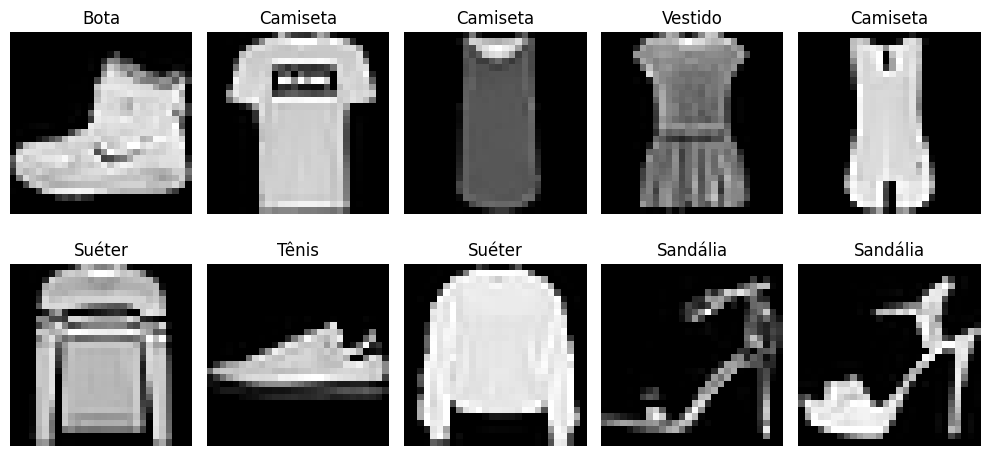

In [3]:
#Etapa 3 — Visualizar as imagens
class_names = [
    "Camiseta", "Calça", "Suéter", "Vestido", "Casaco",
    "Sandália", "Camisa", "Tênis", "Bolsa", "Bota"
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [4]:
#Preparar os dados para a VGG-16
# Adicionar o canal de cor
X_train_vgg = np.expand_dims(X_train, axis=-1)
X_test_vgg = np.expand_dims(X_test, axis=-1)

# Replicar o canal de cinza em três canais
X_train_vgg = np.repeat(X_train_vgg, 3, axis=-1)
X_test_vgg = np.repeat(X_test_vgg, 3, axis=-1)

# Redimensionar para 32 x 32
X_train_vgg = resize(X_train_vgg, [32, 32]).numpy()
X_test_vgg = resize(X_test_vgg, [32, 32]).numpy()

print("Entrada VGG - treino:", X_train_vgg.shape)
print("Entrada VGG - teste:", X_test_vgg.shape)


Entrada VGG - treino: (60000, 32, 32, 3)
Entrada VGG - teste: (10000, 32, 32, 3)


In [5]:
#Etapa 5 — Criar a rede VGG-16
model_vgg = VGG16(
    include_top=True,
    weights=None,
    input_shape=(32, 32, 3),
    classes=10
)

model_vgg.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_vgg.summary()


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │     2,101,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │        40,970 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,638,218 (128.32 MB)

 Trainable params: 33,638,218 (128.32 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Etapa 6 — Treinar a VGG-16
history_vgg = model_vgg.fit(
    X_train_vgg,
    y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)


Epoch 1/3
 54/422 ━━━━━━━━━━━━━━━━━━━━ 1:17:16 13s/step - accuracy: 0.0995 - loss: 2.3037

In [ ]:
#Etapa 7 — Criar a rede neural densa personalizada
model_dense = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),

    layers.Dense(784, activation="relu"),
    layers.Dense(1024, activation="relu"),
    layers.Dense(2048, activation="relu"),
    layers.Dense(2048, activation="relu"),

    layers.Dense(10, activation="softmax")
])

model_dense.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_dense.summary()


In [ ]:
#Etapa 8 — Preparar as imagens para a rede densa
X_train_dense = np.expand_dims(X_train, axis=-1)
X_test_dense = np.expand_dims(X_test, axis=-1)

print("Entrada da rede densa - treino:", X_train_dense.shape)
print("Entrada da rede densa - teste:", X_test_dense.shape)


In [ ]:
#Etapa 9 — Treinar a rede densa
history_dense = model_dense.fit(
    X_train_dense,
    y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)


In [ ]:
#Etapa 10 — Avaliar os dois modelos
loss_vgg, acc_vgg = model_vgg.evaluate(
    X_test_vgg, y_test, verbose=0
)

loss_dense, acc_dense = model_dense.evaluate(
    X_test_dense, y_test, verbose=0
)

print("RESULTADOS FINAIS")
print("-" * 40)
print(f"VGG-16 - Acurácia: {acc_vgg:.4f}")
print(f"VGG-16 - Perda:    {loss_vgg:.4f}")
print(f"Rede densa - Acurácia: {acc_dense:.4f}")
print(f"Rede densa - Perda:    {loss_dense:.4f}")


In [ ]:
#Etapa 11 — Visualizar o desempenho durante o treinamento
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_vgg.history["accuracy"], label="VGG-16 treino")
plt.plot(history_vgg.history["val_accuracy"], label="VGG-16 validação")
plt.plot(history_dense.history["accuracy"], label="Densa treino")
plt.plot(history_dense.history["val_accuracy"], label="Densa validação")
plt.title("Acurácia por época")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_vgg.history["loss"], label="VGG-16 treino")
plt.plot(history_vgg.history["val_loss"], label="VGG-16 validação")
plt.plot(history_dense.history["loss"], label="Densa treino")
plt.plot(history_dense.history["val_loss"], label="Densa validação")
plt.title("Perda por época")
plt.xlabel("Época")
plt.ylabel("Perda")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
#Etapa 12 — Matriz de confusão da melhor rede
if acc_vgg >= acc_dense:
    melhor_modelo = model_vgg
    X_teste_melhor = X_test_vgg
    nome_modelo = "VGG-16"
else:
    melhor_modelo = model_dense
    X_teste_melhor = X_test_dense
    nome_modelo = "Rede densa"

y_pred = np.argmax(
    melhor_modelo.predict(X_teste_melhor, verbose=0),
    axis=1
)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title(f"Matriz de confusão - {nome_modelo}")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    zero_division=0
))
